In [1]:
import pathlib
import sys
import os

# Hacky way to get to root package
if "notebooks" in os.getcwd():
    os.chdir("..")
    

In [2]:
%load_ext autoreload
%autoreload 2
    
import sys
from data_container import load_scouted_data
import pandas as pd
import plotly.express as px
pd.set_option('display.max_columns', None)

In [11]:
scouted_data = load_scouted_data()

scouted_data['Team and Robot'] = scouted_data['Team and Robot'].astype(str)
scouted_data

,Scouter Initials,Match Number,Team and Robot,Starting Position,No Show,autoCarrotO,autoCarrotCakeO,autoCarrotL1,autoCarrotL2,autoCarrotL3,autoCarrotCakeL1,autoCarrotCakeL2,autoCarrotCakeL3,telCarrotO,telCarrotCakeO,telCarrotL1,telCarrotL2,telCarrotL3,telCarrotCakeL1,telCarrotCakeL2,telCarrotCakeL3,Auto Cross Kitchen Line,Auto Robot Stuck or Astop in Auto?,Harvest Haul Carrots,Harvest Haul Carrot Cakes,Defended by opponent?,Opposing Zone Actions,Park,Mechanical Issue?,Died?,Tipped/Fell Over,Scoring Effectiveness,Defense Skill,Yellow/Red Card
0,abc,1,3484,Other,False,1,2,0,3,3,0,2,1,28,12,6,3,9,5,10,10,False,False,1,0,True,Collecting,True,True,False,False,2,3,No Card
1,abc,1,63,Middle Driver Station,False,0,2,4,1,2,0,0,1,28,4,10,19,23,12,12,16,False,False,3,0,True,Defense,True,False,False,False,1,3,No Card
2,abc,1,9406,Alliance Oven/Ramp,False,0,2,3,2,1,2,1,2,6,19,21,19,27,3,7,17,False,False,1,0,True,Defense,True,False,False,False,0,5,No Card
3,abc,1,3504,Alliance Pantry,False,5,1,3,0,2,2,2,1,9,12,25,8,11,9,10,1,False,False,1,0,True,Defense,True,True,False,True,4,3,No Card
4,abc,1,4467,Alliance Pantry,False,2,0,5,2,4,0,2,0,13,8,30,1,1,5,14,15,False,False,0,1,True,Defense,True,True,False,False,4,5,No Card
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,abc,33,4467,Alliance Pantry,False,1,1,3,3,3,0,1,1,23,2,25,2,27,9,4,4,False,False,3,1,True,Collecting,True,True,False,False,1,3,Yellow Card
164,abc,33,9642,Alliance Pantry,False,2,2,5,0,2,2,1,1,5,10,3,4,25,3,11,9,False,False,0,0,True,Collecting,True,False,False,False,2,5,No Card
165,abc,33,2095,Alliance Pantry,False,0,1,2,0,1,0,2,2,19,15,28,27,15,13,5,15,False,False,0,1,True,Collecting,True,False,False,False,4,4,No Card
166,abc,33,4028,Alliance Pantry,False,1,0,5,4,0,0,1,1,7,17,17,28,28,15,0,2,False,False,2,0,True,Defense,True,False,False,False,4,4,No Card


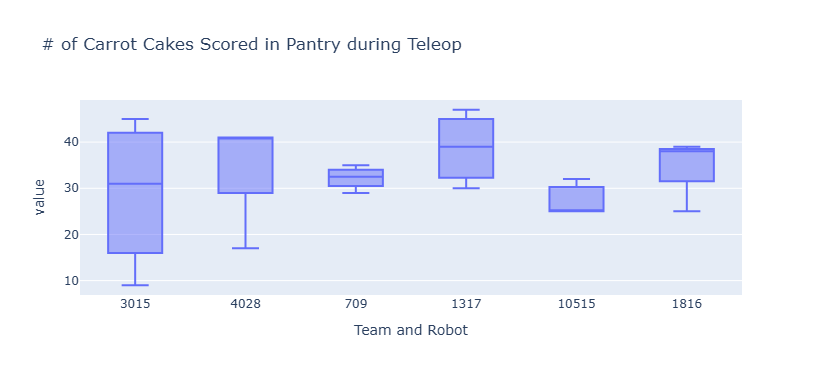

In [19]:
# total pantry carrot cake tele (box + whisker)
scouted_data["telCarrotCake"] = scouted_data["telCarrotCakeL1"] + scouted_data["telCarrotCakeL2"] + scouted_data["telCarrotCakeL3"]
#result = scouted_data.groupby("Team and Robot").mean(numeric_only = True).reset_index()
result = scouted_data[scouted_data["Team and Robot"].isin(["3015", "1317", "10515", "1816", "4028", "709"])]
fig = px.box(result, y=["telCarrotCake"], x="Team and Robot",title=("# of Carrot Cakes Scored in Pantry during Teleop"))
fig
#result

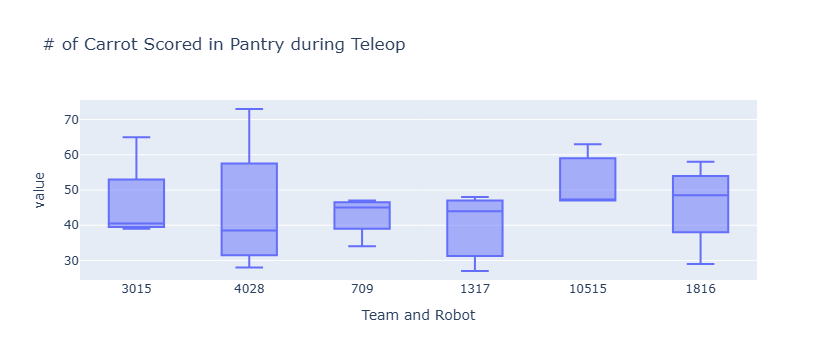

In [20]:
# total pantry  cake tele (box + whisker)
scouted_data["telCarrot"] = scouted_data["telCarrotL1"] + scouted_data["telCarrotL2"] + scouted_data["telCarrotL3"]
#result = scouted_data.groupby("Team and Robot").mean(numeric_only = True).reset_index()
result = scouted_data[scouted_data["Team and Robot"].isin(["3015", "1317", "10515", "1816", "4028", "709"])]
fig = px.box(result, y=["telCarrot"], x="Team and Robot",title=("# of Carrot Scored in Pantry during Teleop"))
fig
#result

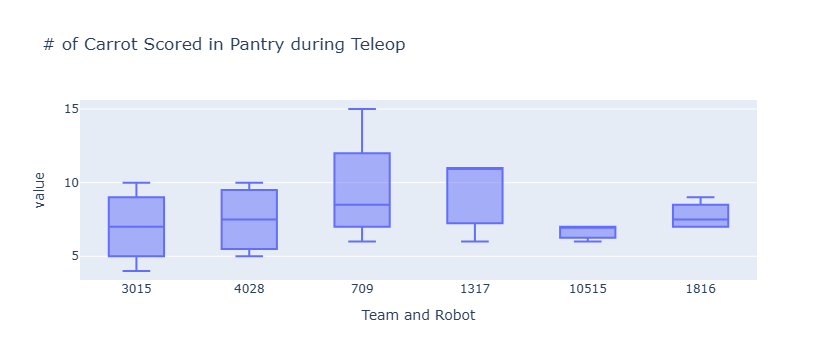

In [21]:
# total pantry cake auto (box + whisker)
scouted_data["autoCarrot"] = scouted_data["autoCarrotL1"] + scouted_data["autoCarrotL2"] + scouted_data["autoCarrotL3"]
#result = scouted_data.groupby("Team and Robot").mean(numeric_only = True).reset_index()
result = scouted_data[scouted_data["Team and Robot"].isin(["3015", "1317", "10515", "1816", "4028", "709"])]
fig = px.box(result, y=["autoCarrot"], x="Team and Robot",title=("# of Carrot Scored in Pantry during Auto"))
fig
#result

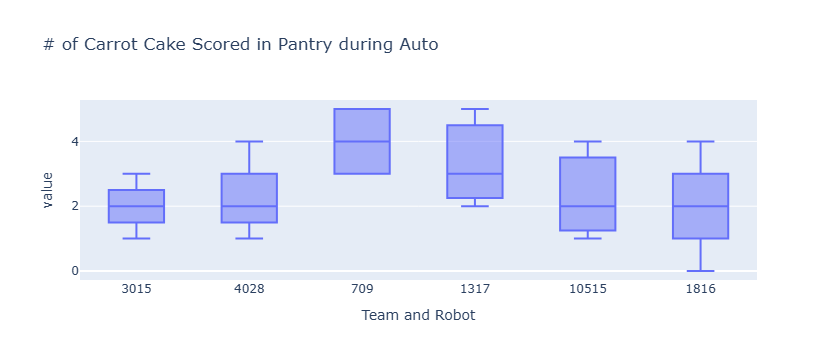

In [22]:
# total pantry cake auto (box + whisker)
scouted_data["autoCarrotCake"] = scouted_data["autoCarrotCakeL1"] + scouted_data["autoCarrotCakeL2"] + scouted_data["autoCarrotCakeL3"]
#result = scouted_data.groupby("Team and Robot").mean(numeric_only = True).reset_index()
result = scouted_data[scouted_data["Team and Robot"].isin(["3015", "1317", "10515", "1816", "4028", "709"])]
fig = px.box(result, y=["autoCarrotCake"], x="Team and Robot",title=("# of Carrot Cake Scored in Pantry during Auto"))
fig
#result

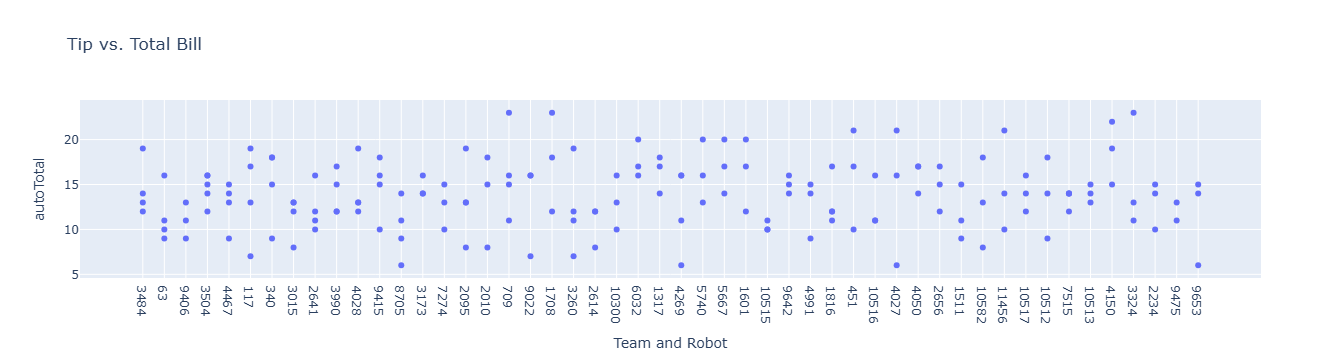

In [33]:
#total points in auto(scatter)

scouted_data["autoTotal"] = scouted_data["autoCarrotCake"] + scouted_data["autoCarrot"]+ scouted_data["autoCarrotO"]+scouted_data["autoCarrotCakeO"]

fig = px.scatter(scouted_data, x="Team and Robot", y="autoTotal", title="Tip vs. Total Bill")
fig